# Praprocessing komentar TikTok (untuk IndoBERTweet)

Notebook ini terdiri dari dua bagian:
1. **EDA**: jumlah video per influencer dan jumlah komentar per video.
2. **Pembersihan komentar**: setiap langkah punya sel sendiri dan mencatat jumlah baris sebelum dan sesudah.

Keputusan yang sudah diambil:
- Emoji dibiarkan.
- URL dan mention (`@username`) dihapus.
- Threshold minimal komentar belum diterapkan (menunggu keputusan).
- `to_scrape.csv` hanya dibaca, tidak diubah.


## 1. Setup path dan konfigurasi

In [1]:
from pathlib import Path
import re
import pandas as pd

FOLDER_DATA = "01_pengumpulan_data"

def find_root():
    """Naik dari folder kerja sampai ketemu folder yang berisi 01_pengumpulan_data."""
    for start in [Path.cwd(), *Path.cwd().parents]:
        if (start / FOLDER_DATA).is_dir():
            return start
    raise FileNotFoundError(f"Folder '{FOLDER_DATA}' tidak ditemukan dari {Path.cwd()}")

ROOT = find_root()
DATA = ROOT / FOLDER_DATA
OUT = ROOT / "02_IndoBert" / "01_praprocessing" / "hasil"   # file pendukung dan log
DATA_OUT = ROOT / "02_IndoBert" / "data"                    # hanya data utama (komentar bersih)
OUT.mkdir(parents=True, exist_ok=True)
DATA_OUT.mkdir(parents=True, exist_ok=True)

PATH_COMMENTS = DATA / "05_scrap_komentar" / "hasil_07_comments" / "comments.csv"
PATH_TO_SCRAPE = DATA / "05_scrap_komentar" / "to_scrape.csv"

MIN_WORDS = 2           # komentar dengan kurang dari ini kata dibuang
USE_LANG_FILTER = False # True = buang komentar yang bukan bahasa Indonesia (butuh langdetect)

print("Root   :", ROOT)
print("Output :", OUT)


Root   : c:\Users\nesha\Tugas_akhir\seleksi-influencer
Output : c:\Users\nesha\Tugas_akhir\seleksi-influencer\02_IndoBert\01_praprocessing\hasil


## 2. EDA: jumlah video per influencer

In [2]:
comments = pd.read_csv(PATH_COMMENTS, dtype=str, keep_default_na=False, encoding="utf-8")
to_scrape = pd.read_csv(PATH_TO_SCRAPE, dtype=str, keep_default_na=False, encoding="utf-8")

for name, df, cols in [("comments", comments, ["username", "video_id", "commenter_username", "comment_text"]),
                       ("to_scrape", to_scrape, ["username", "video_id"])]:
    kurang = [c for c in cols if c not in df.columns]
    if kurang:
        raise KeyError(f"{name}.csv kurang kolom {kurang}. Kolom yang ada: {list(df.columns)}")

print(f"Komentar: {len(comments):,} baris | Target scraping: {len(to_scrape):,} video")


Komentar: 27,073 baris | Target scraping: 794 video


In [3]:
# Target video per influencer
target = to_scrape.groupby("username").size().rename("target_video")

# Video yang punya komentar (dihitung dari comments.csv)
per_video = comments.groupby(["username", "video_id"]).size().rename("n_komentar").reset_index()
ada_komentar = per_video.groupby("username").agg(
    video_ada_komentar=("video_id", "nunique"),
    total_komentar=("n_komentar", "sum"),
    median_komentar_per_video=("n_komentar", "median"),
)

eda = (pd.concat([target, ada_komentar], axis=1)
         .fillna(0)
         .reset_index()
         .rename(columns={"index": "username"})
         .sort_values("total_komentar"))
eda["video_hilang"] = eda["target_video"] - eda["video_ada_komentar"]

print(f"Influencer: {len(eda)}")
print(f"Video target: {int(eda.target_video.sum()):,}")
print(f"Video dengan komentar: {int(eda.video_ada_komentar.sum()):,}")
print(f"Video tanpa komentar: {int(eda.video_hilang.sum()):,}")
eda.to_csv(OUT / "eda_per_influencer.csv", index=False, encoding="utf-8")
eda


Influencer: 46
Video target: 794
Video dengan komentar: 709
Video tanpa komentar: 85


,username,target_video,video_ada_komentar,total_komentar,median_komentar_per_video,video_hilang
9,doktergigitantri,1,0.0,0.0,0.0,1.0
3,citra_amelinda,1,1.0,3.0,3.0,0.0
38,nisaobgyn,6,4.0,8.0,1.5,2.0
14,doktervito,20,12.0,26.0,1.5,8.0
15,dr.deamaulidia,17,9.0,28.0,2.0,8.0
36,meta.hanindita,13,13.0,78.0,3.0,0.0
42,spesialist.kesehatan,9,3.0,106.0,5.0,6.0
18,dr.saddam_ismail,20,12.0,127.0,9.5,8.0
40,reisabrotoasmoro,20,15.0,147.0,3.0,5.0
21,drgfira,13,11.0,158.0,7.0,2.0


In [4]:
# Distribusi jumlah komentar per video (bahan untuk keputusan threshold nanti)
dist = per_video["n_komentar"].clip(upper=10).value_counts().sort_index()
dist.index = [f"{i}" if i < 10 else "10+" for i in dist.index]
print("Jumlah video menurut banyaknya komentar:")
print(dist.to_string())


Jumlah video menurut banyaknya komentar:
1       36
2       50
3       40
4       27
5       21
6       23
7       29
8       23
9       12
10+    448


## 3. Pembersihan komentar

Urutan langkah:
0. Data mentah
1. Komentar kosong
2. Hapus URL dan mention, rapikan spasi
3. Duplikat (video, akun pengirim, dan teks yang sama)
4. Tanpa huruf sama sekali (hanya emoji atau tanda baca)
5. Kurang dari `MIN_WORDS` kata
6. (opsional) bukan bahasa Indonesia

Emoji sengaja tidak diubah.


In [5]:
URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)
MENTION_RE = re.compile(r"@[A-Za-z0-9_.]+")
SPACE_RE = re.compile(r"\s+")

df = comments.copy()
df["comment_text_raw"] = df["comment_text"]
AWAL = len(df)
log = []

def cetak_total(sesudah):
    print(f"Total Komentar Awal :  {AWAL:,}")
    print(f"Total yang dibersihkan :  {AWAL - sesudah:,}")
    print(f"Total akhir :  {sesudah:,}")
    print()

def catat(langkah, sebelum, sesudah):
    log.append({"langkah": langkah, "sebelum": sebelum, "sesudah": sesudah,
                "dibuang": sebelum - sesudah,
                "total_awal": AWAL, "total_dibersihkan": AWAL - sesudah,
                "total_akhir": sesudah})
    print(f"{langkah}  ({sebelum:,} -> {sesudah:,}, dibuang {sebelum - sesudah:,})")
    cetak_total(sesudah)

catat("0. Data mentah", len(df), len(df))


0. Data mentah  (27,073 -> 27,073, dibuang 0)
Total Komentar Awal :  27,073
Total yang dibersihkan :  0
Total akhir :  27,073



In [6]:
# 1. Komentar kosong
n0 = len(df)
df = df[df["comment_text"].str.strip() != ""]
catat("1. Komentar kosong", n0, len(df))


1. Komentar kosong  (27,073 -> 27,073, dibuang 0)
Total Komentar Awal :  27,073
Total yang dibersihkan :  0
Total akhir :  27,073



In [7]:
# 2. Hapus URL dan mention, rapikan spasi
n0 = len(df)
df = df.assign(comment_text=(df["comment_text"]
                             .str.replace(URL_RE, " ", regex=True)
                             .str.replace(MENTION_RE, " ", regex=True)
                             .str.replace(SPACE_RE, " ", regex=True)
                             .str.strip()))
df = df[df["comment_text"] != ""]
catat("2. Hapus URL/mention, jadi kosong", n0, len(df))


2. Hapus URL/mention, jadi kosong  (27,073 -> 26,955, dibuang 118)
Total Komentar Awal :  27,073
Total yang dibersihkan :  118
Total akhir :  26,955



In [8]:
# 3. Duplikat: akun yang sama, video yang sama, teks yang sama
n0 = len(df)
df = df.drop_duplicates(subset=["video_id", "commenter_username", "comment_text"], keep="first")
catat("3. Duplikat (video+akun+teks sama)", n0, len(df))


3. Duplikat (video+akun+teks sama)  (26,955 -> 26,662, dibuang 293)
Total Komentar Awal :  27,073
Total yang dibersihkan :  411
Total akhir :  26,662



In [9]:
# 4. Tanpa huruf sama sekali (hanya emoji, angka, atau tanda baca)
n0 = len(df)
df = df[df["comment_text"].str.contains(r"[A-Za-z]", regex=True)]
catat("4. Tanpa huruf (emoji/tanda baca saja)", n0, len(df))


4. Tanpa huruf (emoji/tanda baca saja)  (26,662 -> 25,659, dibuang 1,003)
Total Komentar Awal :  27,073
Total yang dibersihkan :  1,414
Total akhir :  25,659



In [10]:
# 5. Terlalu pendek
n0 = len(df)
df = df[df["comment_text"].str.split().str.len() >= MIN_WORDS]
catat(f"5. Kurang dari {MIN_WORDS} kata", n0, len(df))


5. Kurang dari 2 kata  (25,659 -> 24,589, dibuang 1,070)
Total Komentar Awal :  27,073
Total yang dibersihkan :  2,484
Total akhir :  24,589



In [11]:
# 6. (opsional) Filter bahasa Indonesia
if USE_LANG_FILTER:
    from langdetect import detect, DetectorFactory
    DetectorFactory.seed = 42

    def is_indonesia(teks):
        try:
            return detect(teks) in ("id", "ms")
        except Exception:
            return False

    n0 = len(df)
    df = df[df["comment_text"].map(is_indonesia)]
    catat("6. Bukan bahasa Indonesia", n0, len(df))
else:
    print("6. Filter bahasa dilewati (USE_LANG_FILTER = False)")
    cetak_total(len(df))


6. Filter bahasa dilewati (USE_LANG_FILTER = False)
Total Komentar Awal :  27,073
Total yang dibersihkan :  2,484
Total akhir :  24,589



## 4. Simpan hasil dan ringkasan

In [12]:
komentar_bersih = df[["username", "video_id", "commenter_username",
                      "comment_text_raw", "comment_text"]].rename(
                          columns={"comment_text": "comment_text_clean"})
komentar_bersih.to_csv(DATA_OUT / "komentar_bersih.csv", index=False, encoding="utf-8")

pd.DataFrame(log).to_csv(OUT / "log_praprocessing.csv", index=False, encoding="utf-8")

akhir = (komentar_bersih.groupby("username")
         .agg(video_setelah_bersih=("video_id", "nunique"),
              komentar_setelah_bersih=("comment_text_clean", "size"))
         .reset_index())
ringkas = eda.merge(akhir, on="username", how="left").fillna(0)
ringkas.to_csv(OUT / "ringkasan_praprocessing.csv", index=False, encoding="utf-8")

print(f"Komentar bersih: {len(komentar_bersih):,} dari {len(comments):,} mentah")
print(f"komentar_bersih.csv -> {DATA_OUT}")
print(f"file pendukung      -> {OUT}")
ringkas.head(10)


Komentar bersih: 24,589 dari 27,073 mentah
komentar_bersih.csv -> c:\Users\nesha\Tugas_akhir\seleksi-influencer\02_IndoBert\data
file pendukung      -> c:\Users\nesha\Tugas_akhir\seleksi-influencer\02_IndoBert\01_praprocessing\hasil


,username,target_video,video_ada_komentar,total_komentar,median_komentar_per_video,video_hilang,video_setelah_bersih,komentar_setelah_bersih
0,doktergigitantri,1,0.0,0.0,0.0,1.0,0.0,0.0
1,citra_amelinda,1,1.0,3.0,3.0,0.0,1.0,2.0
2,nisaobgyn,6,4.0,8.0,1.5,2.0,4.0,7.0
3,doktervito,20,12.0,26.0,1.5,8.0,9.0,21.0
4,dr.deamaulidia,17,9.0,28.0,2.0,8.0,8.0,22.0
5,meta.hanindita,13,13.0,78.0,3.0,0.0,10.0,63.0
6,spesialist.kesehatan,9,3.0,106.0,5.0,6.0,3.0,89.0
7,dr.saddam_ismail,20,12.0,127.0,9.5,8.0,12.0,99.0
8,reisabrotoasmoro,20,15.0,147.0,3.0,5.0,13.0,120.0
9,drgfira,13,11.0,158.0,7.0,2.0,9.0,142.0


## 5. Komentar bersih per influencer

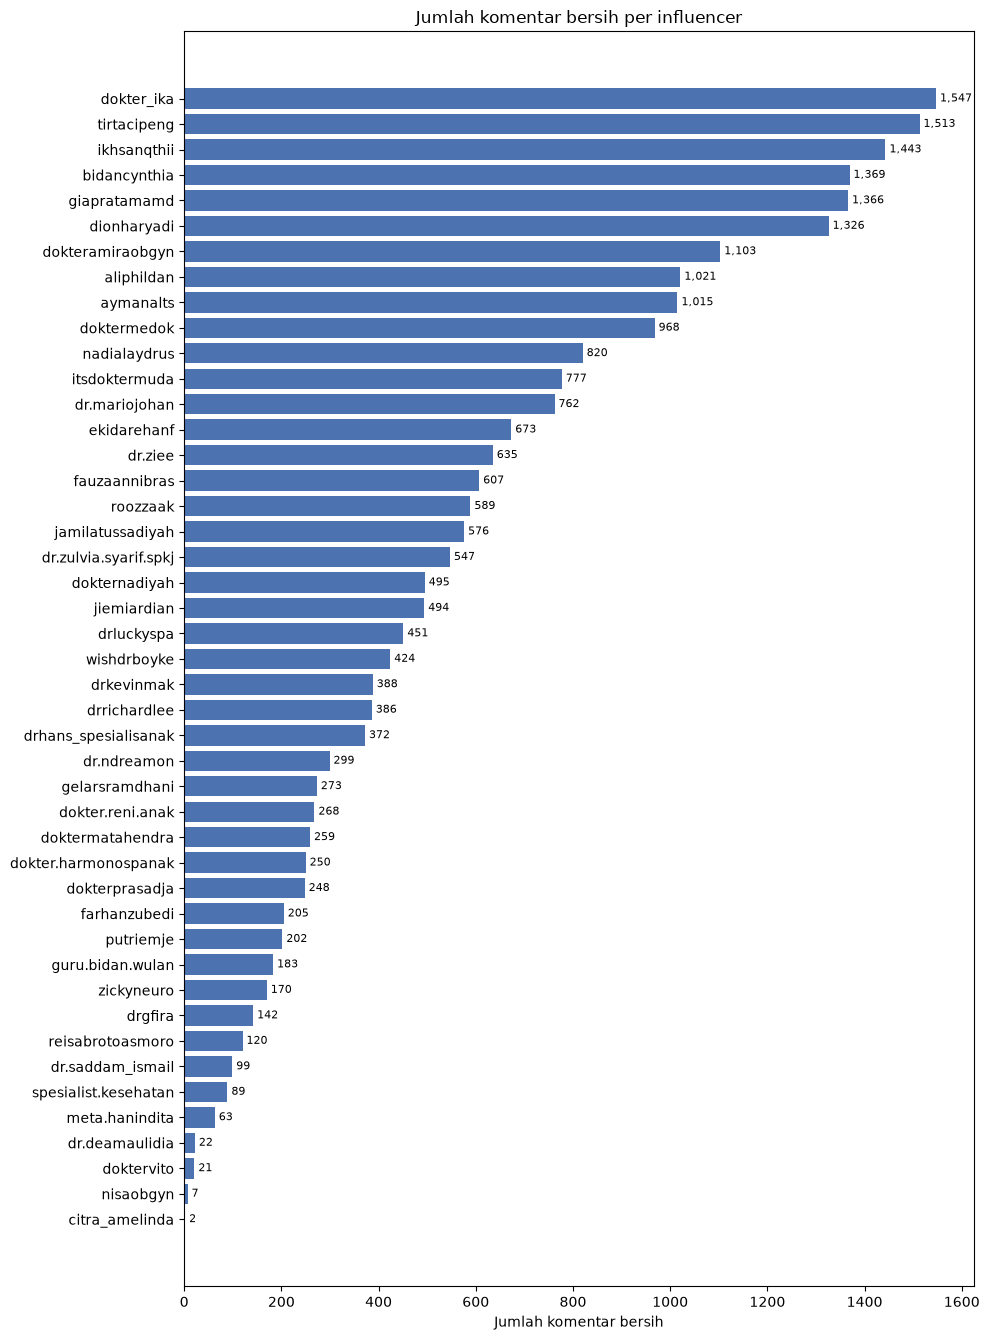

,username,jumlah_komentar
7,dokter_ika,1547
42,tirtacipeng,1513
31,ikhsanqthii,1443
2,bidancynthia,1369
29,giapratamamd,1366
4,dionharyadi,1326
8,dokteramiraobgyn,1103
0,aliphildan,1021
1,aymanalts,1015
10,doktermedok,968


In [13]:
import matplotlib.pyplot as plt

per_inf = (komentar_bersih.groupby("username").size()
           .rename("jumlah_komentar").reset_index()
           .sort_values("jumlah_komentar", ascending=False))
per_inf.to_csv(OUT / "komentar_per_influencer.csv", index=False, encoding="utf-8")

plot_df = per_inf.iloc[::-1]  # urutan dibalik supaya yang terbesar di atas
fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(plot_df))))
ax.barh(plot_df["username"], plot_df["jumlah_komentar"], color="#4C72B0")
ax.set_xlabel("Jumlah komentar bersih")
ax.set_title("Jumlah komentar bersih per influencer")
for y, v in enumerate(plot_df["jumlah_komentar"]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "grafik_komentar_per_influencer.png", dpi=150)
plt.show()

per_inf


## 6. Jumlah sampel gold standard

In [14]:
import math

Z, P, MOE = 1.96, 0.5, 0.03   # kepercayaan 95%, p = 0,5, margin of error 3%
N = len(komentar_bersih)      # populasi = sisa komentar setelah pembersihan

n0 = Z**2 * P * (1 - P) / MOE**2
n_sample = math.ceil(n0 / (1 + (n0 - 1) / N))  # koreksi populasi terbatas

print(f"N (komentar bersih) : {N:,}")
print(f"n0 (tanpa koreksi)  : {math.ceil(n0):,}")
print(f"Sampel minimum (3%) : {n_sample:,}")


N (komentar bersih) : 24,589
n0 (tanpa koreksi)  : 1,068
Sampel minimum (3%) : 1,023


## 7. Pisahkan sampel untuk labeling manual

In [15]:
SEED = 42
UJI_ULANG_PROP = 0.10  # 10% sampel dilabeli dua kali untuk cek konsistensi

N_SAMPLE_PAKAI = 2000  # harus >= sampel minimum (n_sample)
if N_SAMPLE_PAKAI < n_sample:
    raise ValueError(f"N_SAMPLE_PAKAI ({N_SAMPLE_PAKAI}) lebih kecil dari sampel minimum ({n_sample})")

n_ambil = min(N_SAMPLE_PAKAI, len(komentar_bersih))
sampel = komentar_bersih.sample(n=n_ambil, random_state=SEED).reset_index(drop=True)
sampel["label_manual"] = ""
sampel["catatan"] = ""

k = round(len(sampel) * UJI_ULANG_PROP)
sampel["uji_ulang"] = 0
sampel.loc[:k - 1, "uji_ulang"] = 1

path_sampel = OUT / "sampel_labeling.csv"
sampel.to_csv(path_sampel, index=False, encoding="utf-8")

moe = Z * math.sqrt(P * (1 - P) / n_ambil * (N - n_ambil) / (N - 1))  # margin of error yang dicapai
print(f"Sampel untuk dilabeli : {len(sampel):,}")
print(f"Margin of error       : {moe * 100:.2f}%")
print(f"Dilabeli dua kali     : {k:,}")
print(f"Tersimpan di          : {path_sampel}")
sampel.head()


Sampel untuk dilabeli : 2,000
Margin of error       : 2.10%
Dilabeli dua kali     : 200
Tersimpan di          : c:\Users\nesha\Tugas_akhir\seleksi-influencer\02_IndoBert\01_praprocessing\hasil\sampel_labeling.csv


,username,video_id,commenter_username,comment_text_raw,comment_text_clean,label_manual,catatan,uji_ulang
0,aliphildan,7595516244481019154,,i love tiktok,i love tiktok,,,1
1,doktermatahendra,7664166016905153800,,"dok saya pas di cek mesin min 11, tapi pas di ...","dok saya pas di cek mesin min 11, tapi pas di ...",,,1
2,ikhsanqthii,7674176068298788113,,gw mimpi cempe ini menikah😭,gw mimpi cempe ini menikah😭,,,1
3,itsdoktermuda,7602639083843702037,,Aku kalau lagi cuti malah drop 😭 ini termasuk ...,Aku kalau lagi cuti malah drop 😭 ini termasuk ...,,,1
4,dokter_ika,7635652669566127368,,ktanya tinggal nunggu hasil bpom nya keluar ta...,ktanya tinggal nunggu hasil bpom nya keluar ta...,,,1
